11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.2060 - val_loss: 0.1335
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - loss: 0.1220 - val_loss: 0.1119
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.1070 - val_loss: 0.1007
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0994 - val_loss: 0.0956
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.0949 - val_loss: 0.0922
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - loss: 0.0916 - val_loss: 0.0897
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0890 - val_loss: 0.0881
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 0.0868 - val_loss: 0.0852
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0852 - val_loss: 0.0838
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - loss: 0.0839 - val_loss: 0.0826
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0827 - val_

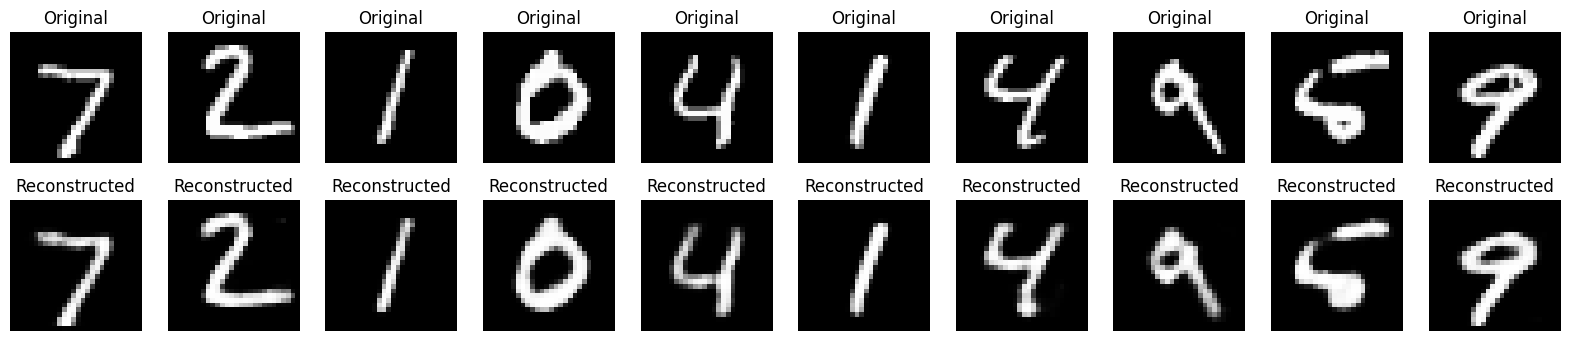

In [1]:
import keras, matplotlib.pyplot as plt
from keras import layers

(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 784).astype('float32') / 255
x_test = x_test.reshape(-1, 784).astype('float32') / 255

inp = layers.Input(shape=(784,))
x = layers.Dense(256, activation='relu')(inp)
x = layers.Dense(128, activation='relu')(x)
code_ = layers.Dense(64, activation='relu')(x)               # compressed representation
x = layers.Dense(128, activation='relu')(code_)
x = layers.Dense(256, activation='relu')(x)
out = layers.Dense(784, activation='sigmoid')(x)

autoencoder = keras.Model(inp, out)
encoder = keras.Model(inp, code_)
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.fit(x_train, x_train, epochs=20, batch_size=256, shuffle=True,
                validation_data=(x_test, x_test))

encoded = encoder.predict(x_test, verbose=0)
decoded = autoencoder.predict(x_test, verbose=0)
print('Compressed shape:', encoded.shape)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    for row, (img, title) in enumerate([(x_test[i], 'Original'), (decoded[i], 'Reconstructed')]):
        plt.subplot(2, n, i + 1 + row * n)
        plt.imshow(img.reshape(28, 28), cmap='gray'); plt.title(title); plt.axis('off')
plt.show()